**Lab 2** for the course of *Selected Topics in Music and Acoustic Engineering* :

***Machine Learning for Audio and Acoustic Engineering***
---

* Student 1: Jorge Cuartero Galindo
* Student 2: Giuliano Di Lorenzo

# **Before you start**

*   Go to "*File*" --> "*Save a copy in Drive*"
*   Open that copy (might open automatically)
*   Then continue below

# **Lab 2: Introduction to ML Methods in Audio**
In this lab we will explore some well-known Machine Learning methods making use of the Scikit-Learn library. We'll go through matrix factorization methods and some popular supervised and unsupervised learning techniques.

---

# Exercise 1. Import libraries

* We need a number of libraries. Import them once to use throughout the document.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")
import librosa, librosa.display
import IPython
from pathlib import Path
import sklearn
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import scale, StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans

---

# Exercise 2. Fetch the Dataset

*   ESC-50: a dataset for Environmental Sound Classification (https://github.com/karolpiczak/ESC-50, https://www.karolpiczak.com/papers/Piczak2015-ESC-Dataset.pdf)
 * 50 classes,  40 files per class, 5s clips
*   Download & unzip the dataset running the cell below. This will take a minute. You will see the new files on the left (folder icon).

In [2]:
!wget https://github.com/karolpiczak/ESC-50/archive/master.zip
!unzip master.zip
!rm master.zip

--2025-03-30 16:36:44--  https://github.com/karolpiczak/ESC-50/archive/master.zip
Resolving github.com (github.com)... 140.82.112.3
Connecting to github.com (github.com)|140.82.112.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master [following]
--2025-03-30 16:36:44--  https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master
Resolving codeload.github.com (codeload.github.com)... 140.82.114.10
Connecting to codeload.github.com (codeload.github.com)|140.82.114.10|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [application/zip]
Saving to: ‘master.zip’

master.zip              [  <=>               ] 615.78M  13.1MB/s    in 43s     

2025-03-30 16:37:27 (14.3 MB/s) - ‘master.zip’ saved [645695005]

Archive:  master.zip
33c8ce9eb2cf0b1c2f8bcf322eb349b6be34dbb6
   creating: ESC-50-master/
   creating: ESC-50-master/.circleci/
  inflating: ESC-50-

---

# Exercise 3. Metadata and analysis I

***Tasks:***
* Use pandas to read the csv file in *ESC-50-master/meta/*
* Print the first elements of the csv. Pandas has a standard function for this.
* Print the list of *unique* class labels in the dataset, and check whether there really are 50 of them

In [40]:
fn_csv = 'ESC-50-master/meta/esc50.csv'

### START CODING
df = pd.DataFrame()
df = pd.read_csv(fn_csv)
print(df[0:5])
unique_classes = df['category'].unique()
print(f'Unique classes: {unique_classes}')
print(f'Count: {unique_classes.size}')
### END CODING

            filename  fold  target        category  esc10  src_file take
0   1-100032-A-0.wav     1       0             dog   True    100032    A
1  1-100038-A-14.wav     1      14  chirping_birds  False    100038    A
2  1-100210-A-36.wav     1      36  vacuum_cleaner  False    100210    A
3  1-100210-B-36.wav     1      36  vacuum_cleaner  False    100210    B
4  1-101296-A-19.wav     1      19    thunderstorm  False    101296    A
Unique classes: ['dog' 'chirping_birds' 'vacuum_cleaner' 'thunderstorm' 'door_wood_knock'
 'can_opening' 'crow' 'clapping' 'fireworks' 'chainsaw' 'airplane'
 'mouse_click' 'pouring_water' 'train' 'sheep' 'water_drops'
 'church_bells' 'clock_alarm' 'keyboard_typing' 'wind' 'footsteps' 'frog'
 'cow' 'brushing_teeth' 'car_horn' 'crackling_fire' 'helicopter'
 'drinking_sipping' 'rain' 'insects' 'laughing' 'hen' 'engine' 'breathing'
 'crying_baby' 'hand_saw' 'coughing' 'glass_breaking' 'snoring'
 'toilet_flush' 'pig' 'washing_machine' 'clock_tick' 'sneezing' 'r

Expected output:
```
    filename            fold  target  category        esc10   src_file  take
0   1-100032-A-0.wav    1     0       dog             True    100032    A
1   1-100038-A-14.wav   1     14      chirping_birds  False   100038    A
2   1-100210-A-36.wav   1     36      vacuum_cleaner  False   100210    A
3   1-100210-B-36.wav   1     36      vacuum_cleaner  False   100210    B
4   1-101296-A-19.wav   1     19      thunderstorm    False   101296    A
```

```
Unique classes: ['dog' 'chirping_birds' ... ]
Count: 50
```

---

# Exercise 4. Metadata and analysis II

* View and listen to some examples in the dataset to get a "feeling" for the sound classes.

dog


chirping_birds


thunderstorm


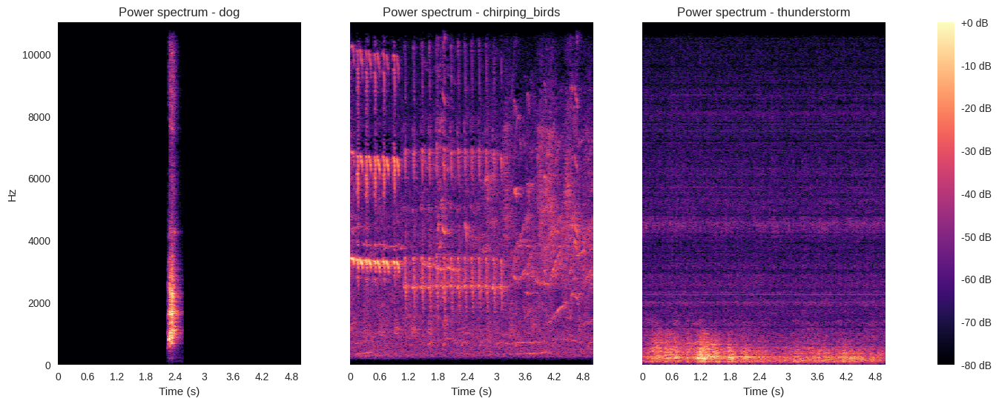

In [41]:
# Setup some filepaths
path = 'ESC-50-master/audio/'

# Select here which 3 samples you want to show
choosen_samples = [0,1,4]

file0 = path + df['filename'][choosen_samples[0]]
file1 = path + df['filename'][choosen_samples[1]]
file2 = path + df['filename'][choosen_samples[2]]

# Show audio player for each file
print(df['category'][choosen_samples[0]])
IPython.display.display(IPython.display.Audio(data=file0))
print(df['category'][choosen_samples[1]])
IPython.display.display(IPython.display.Audio(data=file1))
print(df['category'][choosen_samples[2]])
IPython.display.display(IPython.display.Audio(data=file2))

# Plot mel specs
files = [file0, file1, file2]
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
for i in range(3):
    y, sr = librosa.load(files[i])
    D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    img = librosa.display.specshow(D, y_axis='linear', x_axis='time', sr=sr, ax=ax[i])
    ax[i].set(title='Power spectrum - ' + df['category'][choosen_samples[i]])
    ax[i].label_outer()
    ax[i].set(xlabel='Time (s)')
fig.colorbar(img, ax=ax, format="%+2.f dB")

---

# Exercise 5. ESC-5: Curation

Let's select 2 classes (*our_classes=['dog', 'rooster']*) from ESC-50 to make things a bit faster.

***Tasks:***
* Collect all files that belong to *our_classes*.
* Put the files and their respective classes in separate lists. Make sure their indices are equal (meaning: the value at index 3 of list *A* is related to the value at index 3 of list *B*).
  * Idea 1: Use *df.values* to iterate over the rows of the csv
  * Idea 2: Use *df.query('category in @our_classes')*
* Print the first 5 elements of each list as (file, class)-tuples. Also, print the overall lengths of the lists.

In [42]:
our_classes = ['dog', 'rooster']  # Note: This is also a class map for later

### START CODING ###
filtered_df = df[df["category"].isin(our_classes)]
esc5_X = filtered_df["filename"].values     # audio file names
esc5_y = filtered_df["category"].values     # audio file categories
print(list(zip(esc5_X[:5], esc5_y[:5])))
print(f'Lengths: esc5_X: {esc5_X.size}, esc5_y: {esc5_y.size}')
### END CODING ###

[('1-100032-A-0.wav', 'dog'), ('1-110389-A-0.wav', 'dog'), ('1-26806-A-1.wav', 'rooster'), ('1-27724-A-1.wav', 'rooster'), ('1-30226-A-0.wav', 'dog')]
Lengths: esc5_X: 80, esc5_y: 80


Expected output:
```
[('1-100032-A-0.wav', 'dog'), ('1-110389-A-0.wav', 'dog'), ('1-26806-A-1.wav', 'rooster'), ('1-27724-A-1.wav', 'rooster'), ('1-30226-A-0.wav', 'dog')]
Lengths: esc5_X: 80, esc5_y: 80
```



# Exercise 6. NMF Decomposition
The following code picks one signal of class 'dog' and class 'rooster' and mix both signals together in a new array called 'audiomix'.

**Note:** Listen to the signals and make sure the signal is active in most of the audio duration.

In [43]:
path = 'ESC-50-master/audio/'
dogs_files = esc5_X[esc5_y=='dog']
rooster_files = esc5_X[esc5_y=='rooster']

### START CODING ###
file_index = 6      # change to choose another couple of audio files
signal_0, sr = librosa.load(path + dogs_files[file_index])
signal_1, sr = librosa.load(path + rooster_files[file_index])
### END CODING ###

print(f'Dog example n.°{file_index+1}')
IPython.display.display(IPython.display.Audio(signal_0, rate=sr))
print(f'Rooster example n.°{file_index+1}')
IPython.display.display(IPython.display.Audio(signal_1, rate=sr))

# Compute the mixture of the two signals
audiomix = signal_0/np.max(signal_0) + signal_1/np.max(signal_1)
audiomix = 0.5 * audiomix/np.max(audiomix)
print('Mixture')
IPython.display.display(IPython.display.Audio(audiomix, rate=sr))

Dog example n.°7


Rooster example n.°7


Mixture


<ipython-input-44-bd8a26cfe755>:7: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  librosa.display.specshow(librosa.amplitude_to_db(librosa.stft(signal_0), ref=np.max),
<ipython-input-44-bd8a26cfe755>:12: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  img = librosa.display.specshow(librosa.amplitude_to_db(librosa.stft(signal_1), ref=np.max),


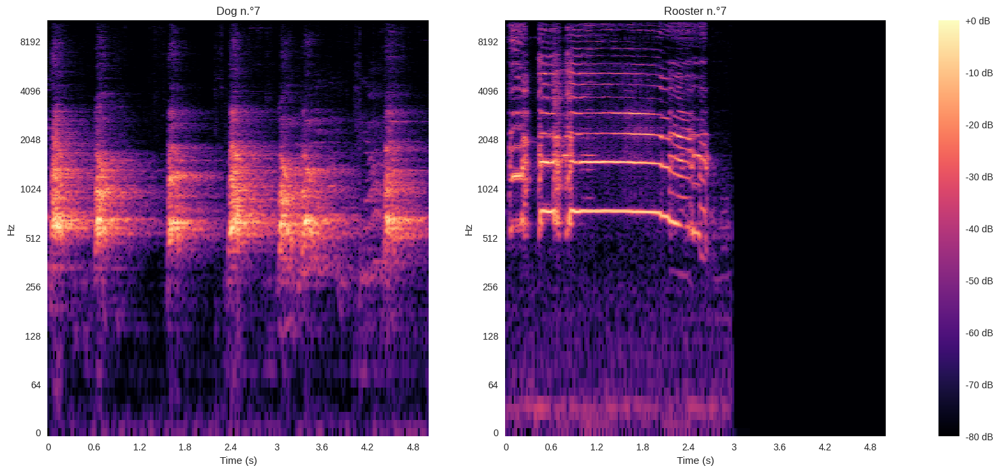

In [44]:
### DEBUGGING ###
'''
We check the spectral content of the selected audio files for dog and rooster (respectively).
'''
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 8))
plt.subplot(1,2,1)
librosa.display.specshow(librosa.amplitude_to_db(librosa.stft(signal_0), ref=np.max),
                         y_axis='log', x_axis='time', sr=sr)
plt.title(f'Dog n.°{file_index+1}')
plt.xlabel('Time (s)')
plt.subplot(1,2,2)
img = librosa.display.specshow(librosa.amplitude_to_db(librosa.stft(signal_1), ref=np.max),
                         y_axis='log', x_axis='time', sr=sr)
plt.title(f'Rooster n.°{file_index+1}')
plt.xlabel('Time (s)')
fig.colorbar(img, ax=ax,format="%+2.f dB")

Now let's compute the spectrogram of the mixture and decompose the magnitude information using NMF with 2 components (see librosa.decompose.decompose):

In [45]:
S = librosa.stft(audiomix)
X, X_phase = librosa.magphase(S)

### START CODING ###
n_components = 2
W, H = librosa.decompose.decompose(X, n_components=n_components)
print(f'Component matrix size: {W.shape}')
print(f'Activation matrix size: {H.shape}')
### END CODING ###

Component matrix size: (1025, 2)
Activation matrix size: (2, 216)


Expected output:
```
(1025, 2) (2, 216)
```

<ipython-input-49-db3257267054>:14: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max),


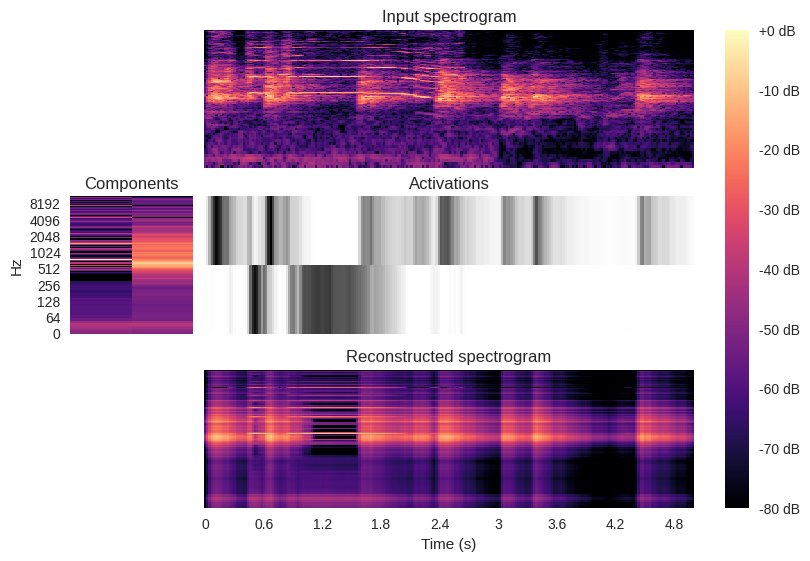

In [49]:
### DEBUGGING ###

'''
We plot together activation and basis matrix, as well as input and output spectogram, to compare the results.
In an ideal case, we expect the basis to look exactly like the input signals before being mixed (under the premise that their spectrum is constant in time).
According to that, the activations should act like a volume control (0 = silent, 1 = full volume).
In our examples, the time activations for the rooster audio should be on the first half only, while the dog activations should be more distributed along the time interval.
We don't obtain the ideal result: this may occur because non-ideal factors appear (like non-constant spectra).
'''

import matplotlib.pyplot as plt
layout = [list(".AAAA"), list("BCCCC"), list(".DDDD")]
fig, ax = plt.subplot_mosaic(layout, constrained_layout=True)
librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max),
                         y_axis='log', x_axis='time', ax=ax['A'])
ax['A'].set(title='Input spectrogram')
ax['A'].label_outer()
librosa.display.specshow(librosa.amplitude_to_db(W,
                                                 ref=np.max),
                         y_axis='log', ax=ax['B'])
ax['B'].set(title='Components')
ax['B'].label_outer()
ax['B'].sharey(ax['A'])
librosa.display.specshow(H, x_axis='time', ax=ax['C'], cmap='gray_r')
ax['C'].set(ylabel='Components', title='Activations')
ax['C'].sharex(ax['A'])
ax['C'].label_outer()
S_approx = W.dot(H)
img = librosa.display.specshow(librosa.amplitude_to_db(S_approx, ref=np.max),
                               y_axis='log', x_axis='time', ax=ax['D'])
ax['D'].set(xlabel='Time (s)')
ax['D'].set(title='Reconstructed spectrogram')
ax['D'].sharex(ax['A'])
ax['D'].sharey(ax['A'])
ax['D'].label_outer()
fig.colorbar(img, ax=list(ax.values()), format="%+2.f dB")

Compare the original and approximated spectrum:

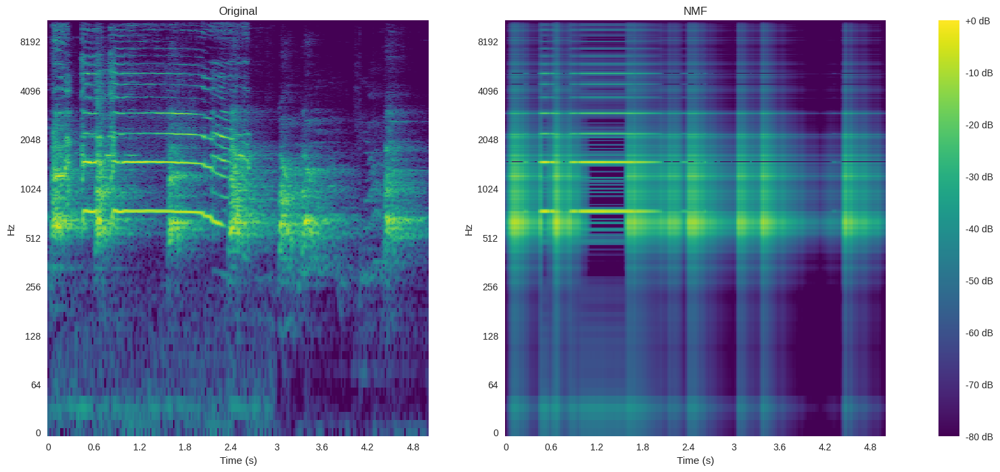

In [50]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 8))

#original
plt.subplot(1,2,1)
librosa.display.specshow(librosa.amplitude_to_db(X+np.finfo(float).eps,ref=np.max),
                         sr=sr, x_axis='time', y_axis='log', cmap='viridis')
plt.title('Original')
plt.xlabel('Time (s)')

#after NMF
plt.subplot(1,2,2)
img = librosa.display.specshow(librosa.amplitude_to_db(W.dot(H)+np.finfo(float).eps,ref=np.max),
                         sr=sr, x_axis='time', y_axis='log', cmap='viridis')
plt.title('NMF')
plt.xlabel('Time (s)')
fig.colorbar(img, ax=ax,format="%+2.f dB")

In [51]:
### DEBUGGING ###
'''
We play the original mixed audio file and the reconstructed one
'''

print('Mixture (original)')
IPython.display.display(IPython.display.Audio(audiomix, rate=sr))
print('Mixture (reconstructed)')
IPython.display.display(IPython.display.Audio(librosa.istft(np.dot(W,H)), rate=sr))

Mixture (original)


Mixture (reconstructed)


Now let's represent the learned spectral patterns and temporal activations for each component:

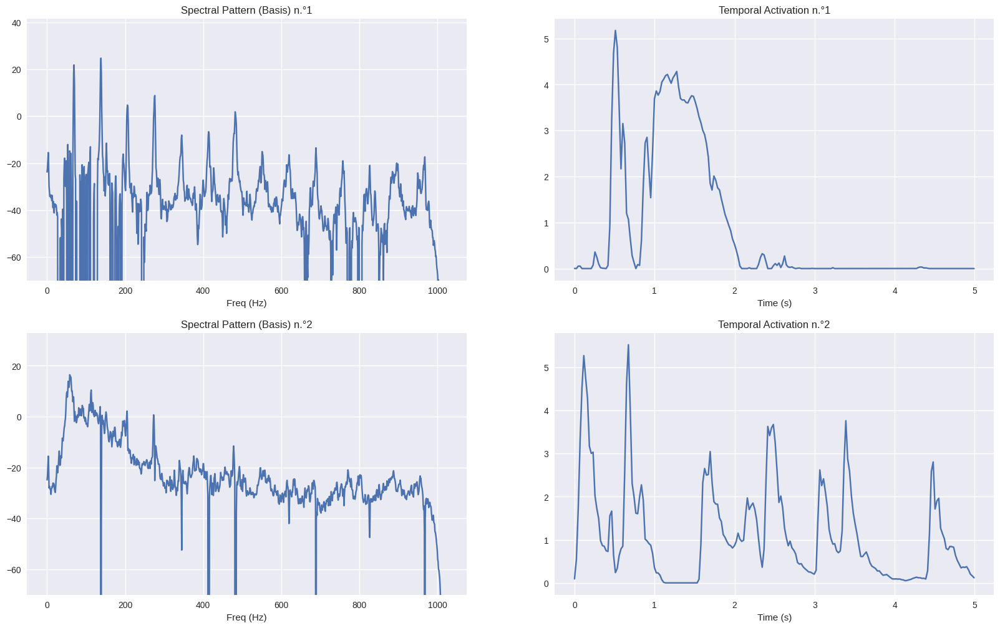

In [52]:
plt.figure(figsize=(20,12))

t_frames = librosa.frames_to_time(np.arange(H.shape[1]))
plot_iter=1
for i in range(n_components):
  plt.subplot(2,n_components,plot_iter)
  plt.plot(20*np.log10(W[:,i]+np.finfo(float).eps))
  plt.xlabel('Freq (Hz)')
  plt.title('Spectral Pattern (Basis) n.°{}'.format(i+1))
  plt.ylim(bottom=-70);
  plot_iter += 1

  plt.subplot(2,n_components,plot_iter)
  plt.plot(t_frames, H[i,:])
  plt.xlabel('Time (s)')
  plt.title('Temporal Activation n.°{}'.format(i+1));
  plot_iter += 1

Finally let's reconstruct the temporal signal of each component (use the phase information of the original mix signal) and listen to the result.

In [53]:
reconstructed_signals = []

### START CODING ###
for i in range(n_components):
    #mag = W[:, i] @ H[i, :]

    component = np.outer(W[:, i],H[i, :]) * X_phase
    signal = librosa.istft(component)
    reconstructed_signals.append(signal)
    print(f'Component n.°{i+1}')
    IPython.display.display(IPython.display.Audio(signal, rate=sr))
### END CODING ###

Component n.°1


Component n.°2


### Observation

In an ideal case, as mentioned before, the spectral pattern (for both components) is exactly the same of the original sound.
That works in case the original audio has constant spectrum in time: that is never the case for ambiental sounds like these.
So, the basis will include all the frequency components that the sound will have within the time interval $ 0-5 \ s $.
It is intuitive to state that the activation doesn't correspond to the single component volume only: different frequency components will be active in different time instants, and the activation should consider that.

Pay attention that the components (1 and 2) are not necessarely in the same order of `our_classes = ['dog', 'rooster']`.

<ipython-input-54-d123ba562ffb>:9: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  librosa.display.specshow(librosa.amplitude_to_db(librosa.stft(signal_0), ref=np.max),
<ipython-input-54-d123ba562ffb>:15: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  img = librosa.display.specshow(librosa.amplitude_to_db(librosa.stft(signal_1), ref=np.max),


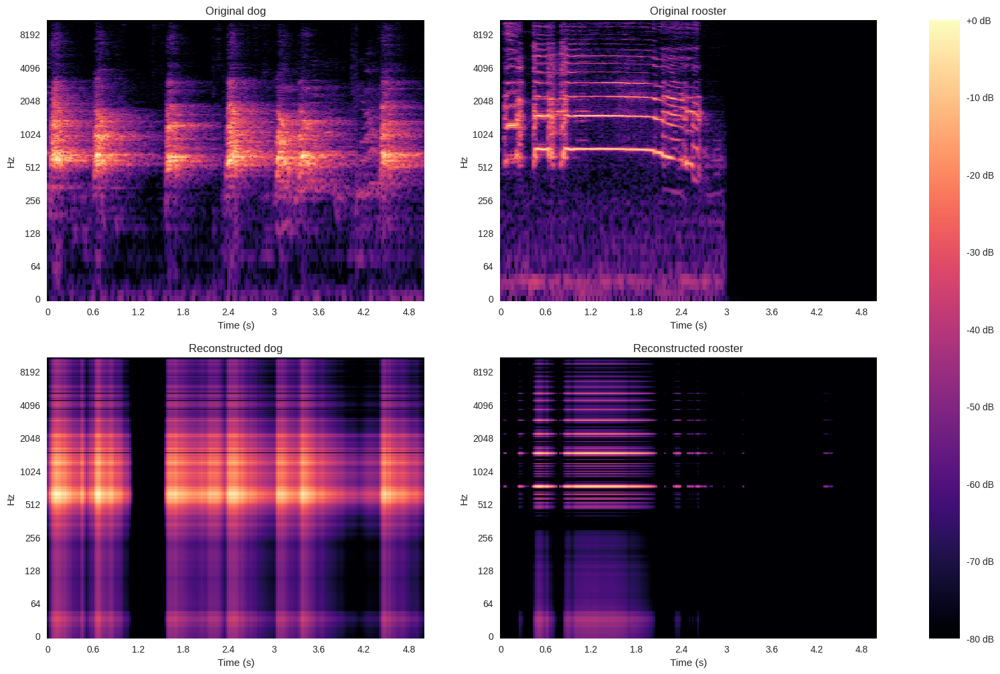

In [54]:
### DEBUGGING ###
'''
We plot the original spectra and the reconstructed ones for both dog and rooster,
to visualize any difference in the reconstruction.
'''

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(20, 12))
plt.subplot(2,2,1)
librosa.display.specshow(librosa.amplitude_to_db(librosa.stft(signal_0), ref=np.max),
                         y_axis='log', x_axis='time', sr=sr)
plt.title('Original dog')
plt.xlabel('Time (s)')

plt.subplot(2,2,2)
img = librosa.display.specshow(librosa.amplitude_to_db(librosa.stft(signal_1), ref=np.max),
                         y_axis='log', x_axis='time', sr=sr)
plt.title('Original rooster')
plt.xlabel('Time (s)')
#fig.colorbar(img, ax=ax,format="%+2.f dB")

plt.subplot(2,2,3)
librosa.display.specshow(librosa.amplitude_to_db(np.outer(W[:, 1],H[1, :]), ref=np.max),
                            y_axis='log', x_axis='time', sr=sr)
plt.title(f'Reconstructed dog')
plt.xlabel('Time (s)')

plt.subplot(2,2,4)
img = librosa.display.specshow(librosa.amplitude_to_db(np.outer(W[:, 0],H[0, :]), ref=np.max),
                            y_axis='log', x_axis='time', sr=sr)
plt.title(f'Reconstructed rooster')
plt.xlabel('Time (s)')
fig.colorbar(img, ax=ax,format="%+2.f dB")

# Exercise 7. Harmonic-Percussive Decomposition
Now, apply librosa's harmonic-percussive source separation to extract again two components.
**Tasks**
*   Compute the harmonic-percussive (see librosa.decompose.hpss)
*   Display the harmonic and the percussive spectrograms
*   Listen to the obtained results
*   Discuss the differences between the standard NMF and the Harmonic-Percussive separation.

Harmonic component


Percussive component


<ipython-input-55-3b7cb896b6ad>:10: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  img = librosa.display.specshow(librosa.amplitude_to_db(Hmm, ref=np.max),
<ipython-input-55-3b7cb896b6ad>:16: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  img = librosa.display.specshow(librosa.amplitude_to_db(Prs, ref=np.max),


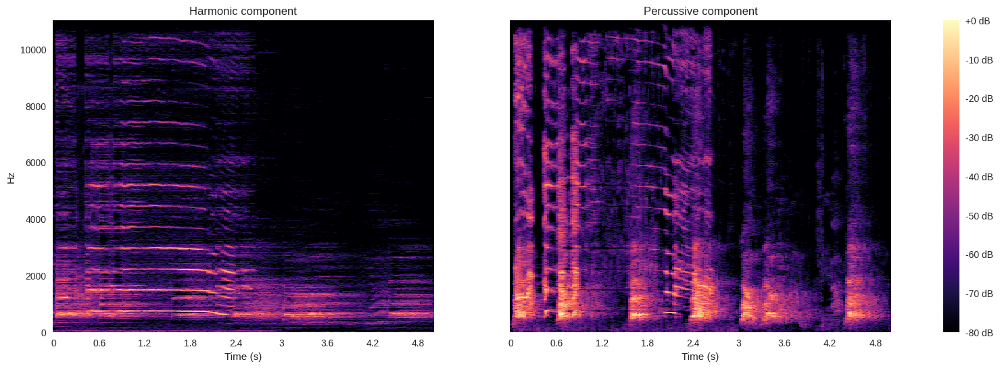

In [55]:
### START CODING ###
Hmm, Prs = librosa.decompose.hpss(S)

print('Harmonic component')
IPython.display.display(IPython.display.Audio(librosa.istft(Hmm), rate=sr))
print('Percussive component')
IPython.display.display(IPython.display.Audio(librosa.istft(Prs), rate=sr))

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 6))
img = librosa.display.specshow(librosa.amplitude_to_db(Hmm, ref=np.max),
                               x_axis='time', y_axis='linear', sr=sr, ax=ax[0])
ax[0].set(title='Harmonic component')
ax[0].label_outer()
ax[0].set(xlabel='Time (s)')

img = librosa.display.specshow(librosa.amplitude_to_db(Prs, ref=np.max),
                               x_axis='time', y_axis='linear', sr=sr, ax=ax[1])
ax[1].set(title='Percussive component')
ax[1].label_outer()
ax[1].set(xlabel='Time (s)')

fig.colorbar(img, ax=ax, format="%+2.f dB")
### END CODING ###

### Observation

The main difference between NMF and Harmonic-Percussive decomposition is that the first technique explores different combinations of spectral basis and time activations looking for the result that best resembles the original mixture spectrum, while the second one is designed to separate harmonic and percussive components from one another.

The consequence is that NMF cannot ensure both good and meaningful results, because there is no guidance that gives any meaning to the basis.
Of course, this depends a lot on the problem of interest: in our case, as we mentioned before, it is very hard to obtain a proper result with two componenst (two basis) when the input has that much time variability of the spectra.

About Harmonic-Percussive separation, the results obtained can be much cleaner in terms of audio quality, but does not have any meaning when separating two generic audio sources.
This is because it splits the mixture into a percussive component (capturing all transients and vertical lines in the spectrum) and an harmonic component (capturing the more sustained spectral components).
Even though this process is very effective, that doesn't necessarely mean we are obtaining something valuable: the premise here is that one of the two sound sources has only harmonic components, while the other has only percussive components.
In our case, that logic may work just fine if considering the dog audio as mainly percussive, while the rooster audio as mainly harmonic.
Generally, though, this technique doesn't ensure a successfull source separation.

In conclusion, neither NMF nor HPSS are optimal for this scenario, but the second one seems to work way better.
As usual, tuning these methods or paying attention to the audio characteristics can bring to better results.
For example, we may modify the margin factor in the HPSS computation to get rid of impurities in both resulting components (at cost of deleting any residual component).

# Exercise 8. Feature Extraction
Compute the mean ZCR and standard deviation of the spectral flatness for the examples in signals_0 (dogs) and signals_1 (rooster). Define a function to extract those features (call it 'extract_features') and store the extracted features into two arrays: 'dog_features' and 'rooster_features'

In [56]:
# Function definition
def extract_features(signal):
    ### START CODING ###
    mean = np.mean(librosa.feature.zero_crossing_rate(signal))
    std = np.std(librosa.feature.spectral_flatness(y=signal))

    return [mean, std]
    ### END CODING ###

In [57]:
# Feature Extraction
### START CODING ###
signal_d = [librosa.load(path + file)[0] for file in dogs_files]
signal_r = [librosa.load(path + file)[0] for file in rooster_files]

dog_features = np.array([extract_features(signal) for signal in signal_d])
rooster_features = np.array([extract_features(signal) for signal in signal_r])

print(dog_features.shape)       # 40 samples and 2 feature each
print(rooster_features.shape)
### END CODING ###

(40, 2)
(40, 2)


Expected output:
```
(40, 2)
(40, 2)
```

Represent the histograms for each feature for the two classes and discuss which of the two features seems to be better for classification.

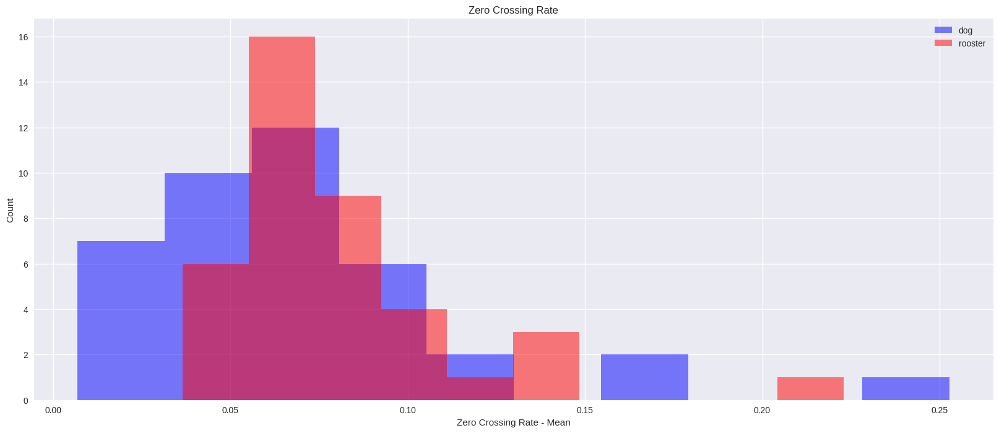

In [58]:
# First feature (ZCR)
plt.figure(figsize=(20,8))
plt.hist(dog_features[:,0], color='b', alpha=0.5, bins=10)
plt.hist(rooster_features[:,0], color='r', alpha=0.5, bins=10)
plt.title('Zero Crossing Rate')
plt.legend(('dog','rooster'))
plt.xlabel('Zero Crossing Rate - Mean')
plt.ylabel('Count');

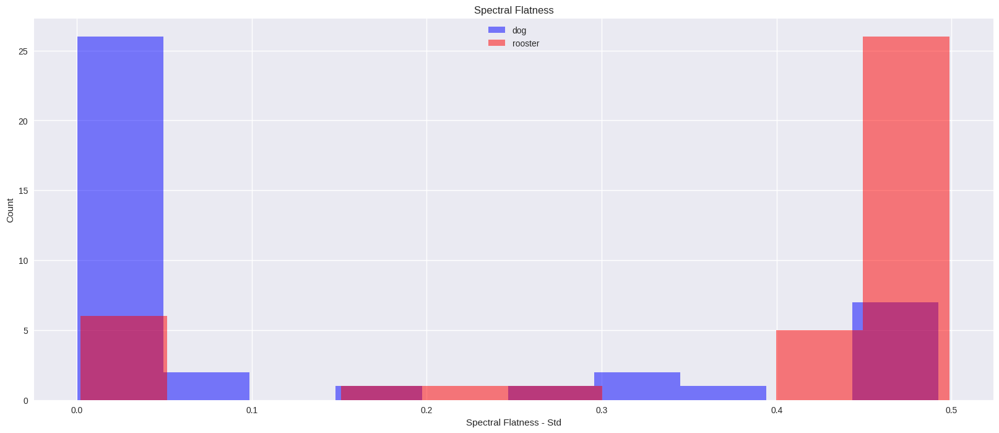

In [59]:
# Second feature (SF)
### START CODING ###
plt.figure(figsize=(20,8))
plt.hist(dog_features[:,1], color='b', alpha=0.5, bins=10)
plt.hist(rooster_features[:,1], color='r', alpha=0.5, bins=10)
plt.title('Spectral Flatness')
plt.legend(('dog','rooster'))
plt.xlabel('Spectral Flatness - Std')
plt.ylabel('Count');
### END CODING ###

### Observation

The purpose of these histograms is to see how each feature behaves for the different classes, so we can use them to classify different audio files based on those features.
In order to do this, we want the features to present clear differences between one class and the other.

Looking at the two previous plots, we observe that the standard deviation of the Spectral Flatness gives us a much better result for the classes discrimination: most rooster audio values tend to 0.5, while most dog audio values tend to 0.

To understand why both features behave like this, we need to understand which information they contain.

The Zero-Crossing Rate tells us how many times the signal changes sign.
These values are obtained for different windows of the signal, obtaining an array of values.
If we take a look to these values, we observe that they tend to 0 whenever there is silence, and take higher values whenever there is sound.
In addition to that, higher frequency components have higher ZCR values because they describe faster changes.

With this in mind, we can see that the dog signals tend to be more chaothic (i.e. more percussive), with a wide spread in the ZCR values: these signals are characterized by percussive sounds that continuously change in frequency.
On the other hand, rooster signals show constant ZCR values in time in different parts of their spectra, because those sounds are more constant.
Additionally, rooster audios tend to have higher ZCR values because they generally have higher frequency components.

With this general idea in mind, the last step is to consider the average.
If we were using the ZCR itself, maybe we could easily differenciate between dog and rooster, but doing the average erases most of the obtained information.
Dog audios generally show lower values of ZCR, very noisy but sustained over time.
On the other hand, rooster audio have higher and more constant ZCR values.
The problem is that half of many rooster audios is silence, where the ZCR is 0.
When doing the averages, both cases lead to the same results, and this is the reason why the mean of the ZCR is not very effective, even though the ZCR itself shows clear differences.

Going on with the Spectral Flatness, this parameter measures the ratio between geometric and arithmetic mean of the frequency bins for a certain instant of time.
Arithmetic average is always greater (or equal) than the geometric one, so this ratio is contained between 0 and 1.
In general, flat spectra (all frequencies have same amplitude) have SF tending to 1, because both averages return the same result, while other cases will have lower values, with SF tending to 0 when the spectrum has only single peaks.

In dog audios, we have more continuous sound streams (there's not much room for silence), which leads to having low SF values (around 0, but they can vary) for almost all the time interval.
This observation is more valid the more barking we have: the transitions between the barkings may be more silent or not, resulting in less stable SF values.
On the other hand, rooster audios have a lot of silent parts (almost half of the time interval), so the SF will tend to polarize: it has low values when there is sound (almost 0 for all the sound duration), and high values when there is silence (almost 1 because of the background noise).
As a result, the dog audios have generally lower SF values with respect to the rooster audios.

When we apply the standard deviation to the SF, we measure the variability or dispersion from the mean in the SF distribution.
Most of the times, we have dog spectra that slowly vary around 0, while rooster spectra usually have 0 for half of the time interval and 1 for the remaining part.

The consequence of this is that dog audio will present very low SF-std, while the rooster audio will present the higher possible values, that is 0.5 for distributions between 0 and 1 (as we can confirm in our data).
Of course, this works only because of the way the audios where recorded.
If either the rooster audios didn't have that much silence or the dog barks where more isolated (i.e. `idx = 5`), we would be facing a completely different situation.
In some way, it's the distrubution of the silence (and not the difference between the animals itself) what allow us to discriminate the two classes.
Also, another important contribution is given to the fact we don't consider ZCR and SF as they are, but we process them (taking the mean or the std).

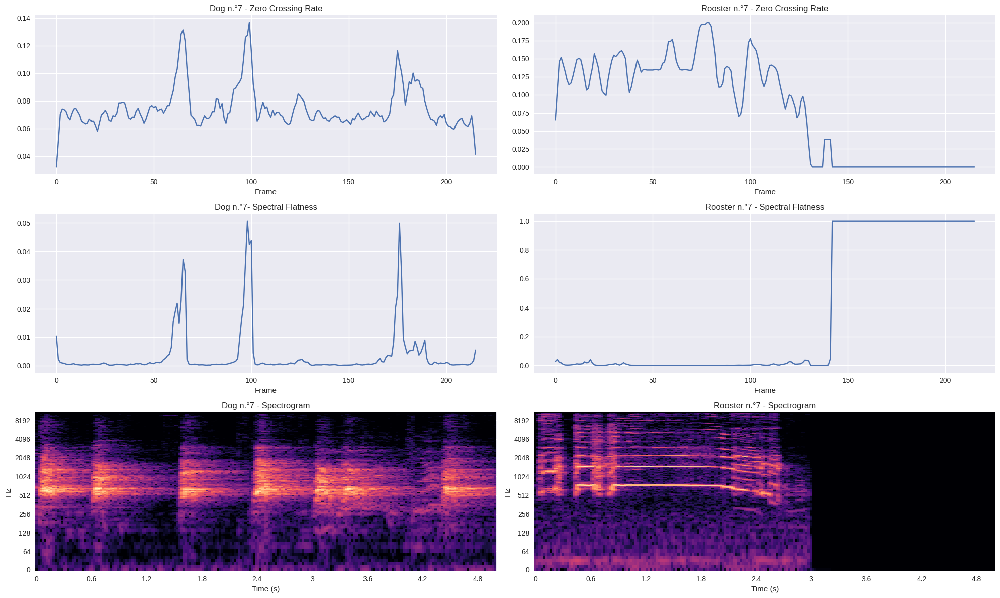

Dog example n.°7


Rooster example n.°7


In [63]:
### DEBUGGING ###
'''
This cell shows the spectral flatness of each window, in order to get in idea of its std.
We suppose that the silence usually has a value of 1, while sounds tend to 0, even though different audio files may differ in that (some audio files, i.e. dog n.3, are more noisy).
This means that the std will depend on the proportions of sound and silence, being maximum when half of the audio is silence and the other half is sound (std = 0.5).
For the ZCR, the behaviour is very similar, with more variability and intermediate values.
'''

idx = 6
sgn_dog = librosa.load(path + dogs_files[idx])[0]
sf = librosa.feature.spectral_flatness(y=sgn_dog)
zcr = librosa.feature.zero_crossing_rate(y=sgn_dog)

plt.figure(figsize=(20, 12))

# Zero Crossing Rate - Dog
plt.subplot(3, 2, 1)
plt.plot(zcr.reshape(-1))
plt.title(f'Dog n.°{idx+1} - Zero Crossing Rate')
plt.xlabel('Frame')

# Spectral Flatness - Dog
plt.subplot(3, 2, 3)
plt.plot(sf.reshape(-1))
plt.title(f'Dog n.°{idx+1}- Spectral Flatness')
plt.xlabel('Frame')

# Spectrogram - Dog
plt.subplot(3, 2, 5)
librosa.display.specshow(librosa.amplitude_to_db(librosa.stft(sgn_dog), ref=np.max),
                         y_axis='log', x_axis='time', sr=sr)
plt.title(f'Dog n.°{idx+1} - Spectrogram')
plt.xlabel('Time (s)')

sgn_rst = librosa.load(path + rooster_files[idx])[0]
sf = librosa.feature.spectral_flatness(y=sgn_rst)
zcr = librosa.feature.zero_crossing_rate(y=sgn_rst)

# Zero Crossing Rate - Rooster
plt.subplot(3, 2, 2)
plt.plot(zcr.reshape(-1))
plt.title(f'Rooster n.°{idx+1} - Zero Crossing Rate')
plt.xlabel('Frame')

# Spectral Flatness - Rooster
plt.subplot(3, 2, 4)
plt.plot(sf.reshape(-1))
plt.title(f'Rooster n.°{idx+1} - Spectral Flatness')
plt.xlabel('Frame')

# Spectrogram - Rooster
plt.subplot(3, 2, 6)
librosa.display.specshow(librosa.amplitude_to_db(librosa.stft(sgn_rst), ref=np.max),
                         y_axis='log', x_axis='time', sr=sr)
plt.title(f'Rooster n.°{idx+1} - Spectrogram')
plt.xlabel('Time (s)')

plt.tight_layout()
plt.show()

# Audio files
print(f'Dog example n.°{idx+1}')
IPython.display.display(IPython.display.Audio(sgn_dog, rate=sr))
print(f'Rooster example n.°{idx+1}')
IPython.display.display(IPython.display.Audio(sgn_rst, rate=sr))

# Exercise 9. Principal Component Analysis
Redefine the feature extractor to extract 3 features, adding to the previous ones the mean value of the spectral centroid (see librosa.feature.spectral_centroid).

In [64]:
# Function definition
def extract_features(signal):
    ### START CODING ###
    mean_zcr = np.mean(librosa.feature.zero_crossing_rate(signal))
    std = np.std(librosa.feature.spectral_flatness(y=signal))
    mean_sc = np.mean(librosa.feature.spectral_centroid(y=signal))

    return [mean_zcr, std, mean_sc]
    ### END CODING ###

In [65]:
# Feature Extraction
### START CODING ###
signal_d = [librosa.load(path + file)[0] for file in dogs_files]
signal_r = [librosa.load(path + file)[0] for file in rooster_files]

dog_features = np.array([extract_features(signal) for signal in signal_d])
rooster_features = np.array([extract_features(signal) for signal in signal_r])

print(dog_features.shape)       # 40 samples and 2 feature each
print(rooster_features.shape)
### END CODING ###

(40, 3)
(40, 3)


Expected output:
```
(40, 3)
(40, 3)
```

Create a matrix 'feature_table' stacking all the features a use sklearn 'scale' over such matrix. Create as well a label vector indicating the true label for each row of 'feature_table'

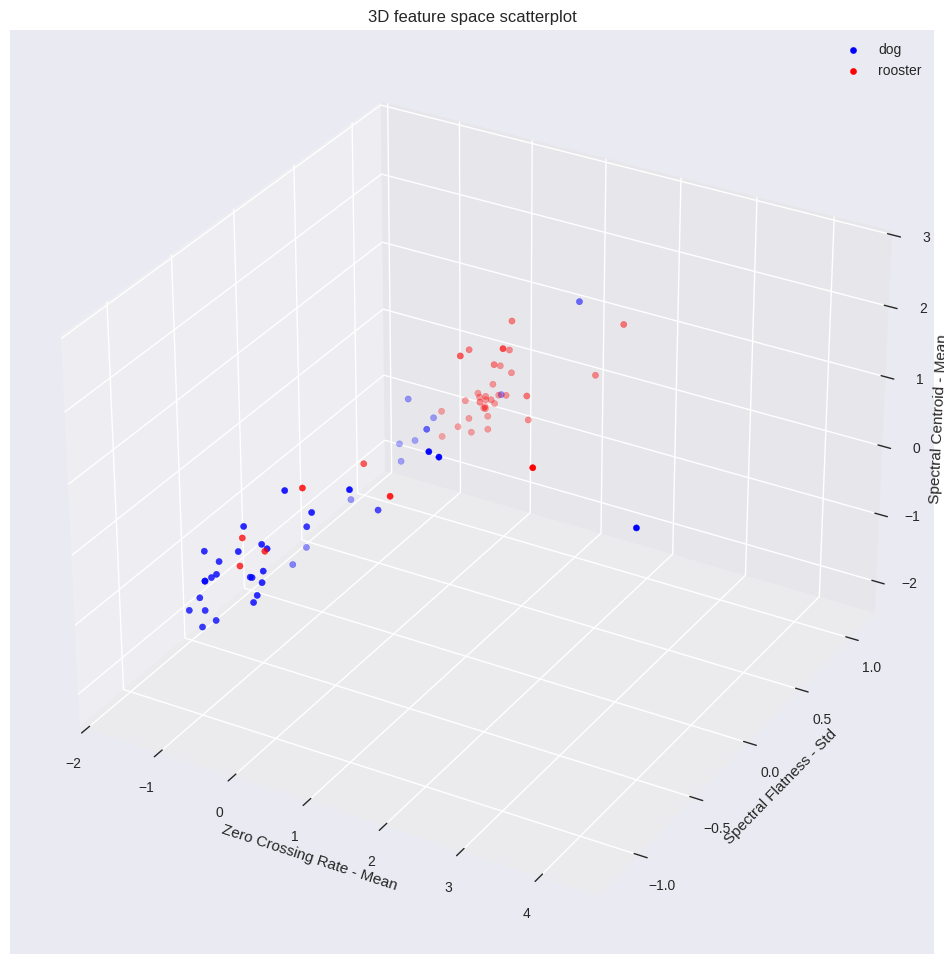

In [66]:
from sklearn.preprocessing import scale

### START CODING ###
feature_table = np.vstack([dog_features, rooster_features])
labels_gt = np.hstack([np.ones(len(dog_features)), np.zeros(len(rooster_features))])
### END CODING ###

# Scale the features
training_features = scale(feature_table, axis=0)

fig = plt.figure(figsize=(12,12))
ax = fig.add_subplot(1,1,1, projection='3d')
ax.scatter(training_features[labels_gt==1,0], training_features[labels_gt==1,1], training_features[labels_gt==1,2], c='b')
ax.scatter(training_features[labels_gt==0,0], training_features[labels_gt==0,1], training_features[labels_gt==0,2], c='r');
ax.legend(('dog','rooster'))
ax.set_title('3D feature space scatterplot')
ax.set_xlabel('Zero Crossing Rate - Mean')
ax.set_ylabel('Spectral Flatness - Std')
ax.set_zlabel('Spectral Centroid - Mean');

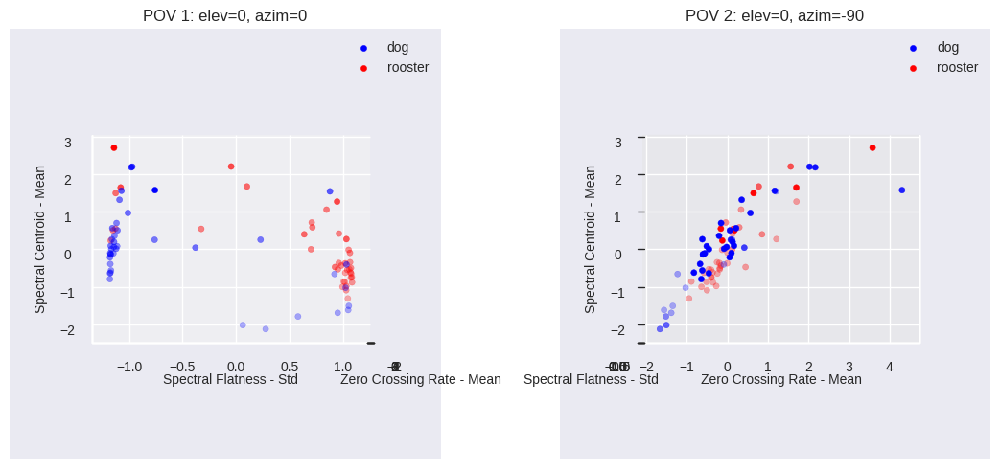

In [67]:
### DEBUGGING ###
'''
The purpose here is to check that the actual distribution matches what we could see before, usign different point of views.
Consider that now the data will be displaced due to `scale()`.
The first plot shows the same as before: the dog ZCR-mean tends to -1, while the rooster one tends to +1 (before it was 0 and 0.5, but we still see the polarization).
Similarly it occurs in the second plot, where both classes behave similarly and tend to low values.
'''

from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 5))
view_angles = [(0, 0), (0, -90)]

for i, (elev, azim) in enumerate(view_angles, 1):
    ax = fig.add_subplot(1, 2, i, projection='3d')
    ax.scatter(training_features[labels_gt == 1, 0], training_features[labels_gt == 1, 1], training_features[labels_gt == 1, 2], c='b', label='dog')
    ax.scatter(training_features[labels_gt == 0, 0], training_features[labels_gt == 0, 1], training_features[labels_gt == 0, 2], c='r', label='rooster')

    ax.legend()
    ax.set_title(f'POV {i}: elev={elev}, azim={azim}')

    ax.set_xlabel('Zero Crossing Rate - Mean', fontsize=10, labelpad=10)
    ax.set_ylabel('Spectral Flatness - Std', fontsize=10, labelpad=10)
    ax.set_zlabel('Spectral Centroid - Mean', fontsize=10, labelpad=10)

    if azim == 0:
        ax.get_yaxis().set_visible(False)
    elif azim == -90:
        ax.get_xaxis().set_visible(False)

    ax.set_proj_type('ortho')
    ax.dist = 10
    ax.view_init(elev=elev, azim=azim)

plt.tight_layout()
plt.show()


Now apply PCA for reducing the dimensionality (see sklearn.decomposition.PCA) to two dimensions using whiten='true' and plot the corresponding scatterplot:

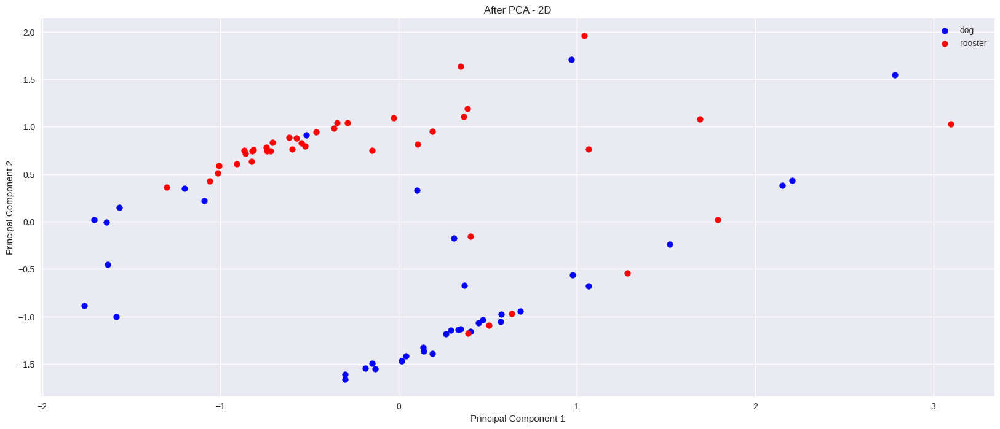

In [68]:
### START CODING ###
#Create dimensionality reduction model
X = training_features
model_pca = sklearn.decomposition.PCA(n_components=2, whiten=True)
Y = model_pca.fit_transform(X)  # fitting `model` to the features
                                # and applying

#Plotting The Result
plt.figure(figsize=(20,8))
plt.scatter(Y[labels_gt==1,0], Y[labels_gt==1,1], c='b')
plt.scatter(Y[labels_gt==0,0], Y[labels_gt==0,1], c='r')
plt.title('After PCA - 2D')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(('dog', 'rooster'));
#from 3d --> 2d
### END CODING ###

# Exercise 10. Support Vector Machine

Fit a linear SVM classifier with parameter C=1 to the PCA transformed data. Use the following helper function to draw the classifier hyperplanes of interest:

In [69]:
def draw_classplane(ax,model,xrange):
  w = model.coef_[0]
  b = model.intercept_[0]
  a = -w[0] / w[1]
  xx = np.linspace(xrange[0], xrange[1])
  yy = a * xx - (b/ w[1])
  margin = 1 / np.sqrt(np.sum(w** 2))
  yy_down = yy - np.sqrt(1 + a ** 2) * margin
  yy_up = yy + np.sqrt(1 + a ** 2) * margin
  ax.plot(xx, yy, 'k-')
  ax.plot(xx, yy_down, 'k--')
  ax.plot(xx, yy_up, 'k--')

In [70]:
### START CODING ###
#Create dimensionality reduction model
model_lsvm = sklearn.svm.SVC(C=1, kernel='linear')
model_lsvm.fit(Y, labels_gt)
labels_pred = model_lsvm.predict(Y)
### END CODING ###

Represent two subplots to compare the ground truth data and the classification result. Plot the classification hyperplanes and margin using the provided function 'draw_classplane'

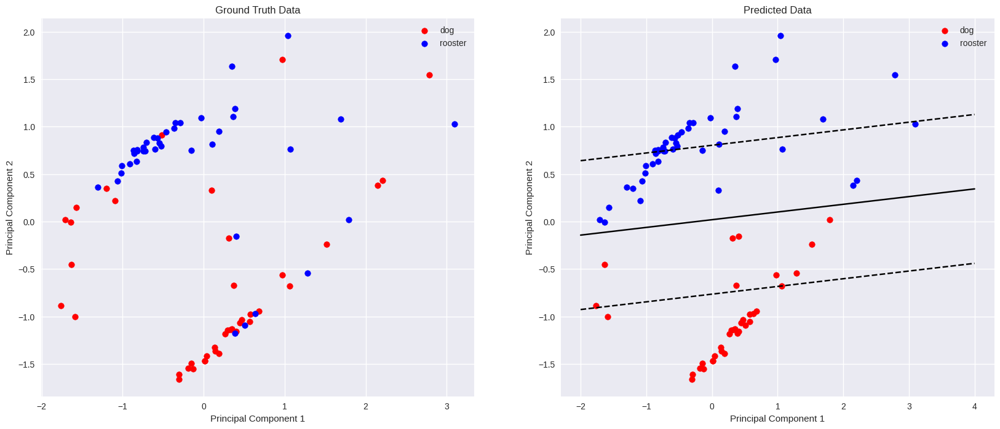

In [71]:
### START CODING ###
plt.figure(figsize=(20,8))

#Ground Truth Data
plt.subplot(1,2,1)
plt.scatter(Y[labels_gt==1,0], Y[labels_gt==1,1], c='r')
plt.scatter(Y[labels_gt==0,0], Y[labels_gt==0,1], c='b')
plt.title('Ground Truth Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(('dog', 'rooster'))

#Classification Result
plt.subplot(1,2,2)
plt.scatter(Y[labels_pred==1,0], Y[labels_pred==1,1], c='r')
plt.scatter(Y[labels_pred==0,0], Y[labels_pred==0,1], c='b')
plt.title('Predicted Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(('dog', 'rooster'))
### END CODING ###

#Draw Hyperplane and margins
draw_classplane(plt.gca(), model_lsvm, (-2,4));

Compute the accuracy of the classification result (use sklearn.metrics.accuracy_score).

In [72]:
### START CONDING ###
acc = sklearn.metrics.accuracy_score(labels_gt, labels_pred)
print(f'Accuracy: {acc*100}%')
### END CODING

Accuracy: 78.75%


Expected output (might differ slightly):
```
Accuracy:  0.7875
```


Now, apply a RBF kernel for non-linear classification:

In [73]:
### START CODING ###
penalty = 1
model_rbf = sklearn.svm.SVC(C=penalty)
model_rbf.fit(Y, labels_gt)
labels_pred_rbf = model_rbf.predict(Y)
### END CODING ###

Draw the resulting classification contour and compute the accuracy:

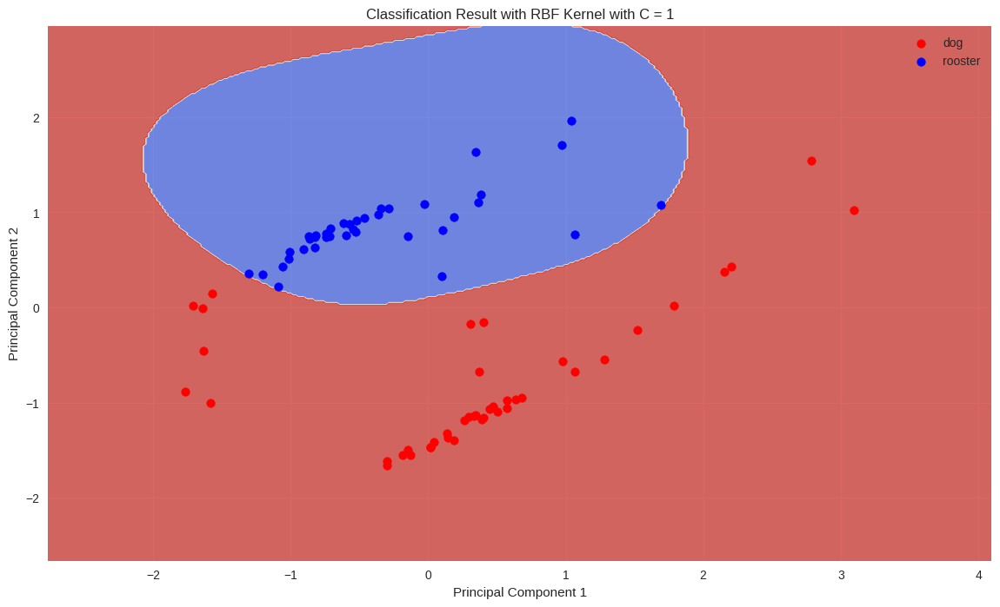

In [74]:
plt.figure(figsize=(14,8))

#for representation purposes
h = 0.02
x_min, x_max = Y[:,0].min() -1 , Y[:,0].max() +1
y_min, y_max = Y[:,1].min() -1 , Y[:,1].max() +1
xx, yy = np.meshgrid(np.arange(x_min,x_max,h), np.arange(y_min, y_max,h))

#display the boundary by predicting on every point on the grid
Z = model_rbf.predict(np.c_[ xx.ravel(), yy.ravel()])
# Put the result into color plot
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap = plt.cm.coolwarm, alpha = 0.8)

plt.xlim(xx.min(), xx.max());
plt.ylim(yy.min(), yy.max());

plt.scatter(Y[labels_pred_rbf==1,0],Y[labels_pred_rbf==1,1],c='r')
plt.scatter(Y[labels_pred_rbf==0,0],Y[labels_pred_rbf==0,1],c='b')
plt.title('Classification Result with RBF Kernel with C = {}'.format(penalty))
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(('dog', 'rooster'));

In [75]:
### START CODING ###
acc_rbf = sklearn.metrics.accuracy_score(labels_gt, labels_pred_rbf)
print(f'Accuracy: {acc_rbf*100}%')
### END CODING ###

Accuracy: 85.0%


Expected output (might differ slightly):
```
Accuracy:  0.85
```

Experiment with different parameters of C. Try different values also for the "gamma" parameter of the RBF kernel.

Find a combination of parameters representing an overfitting and underfitting.

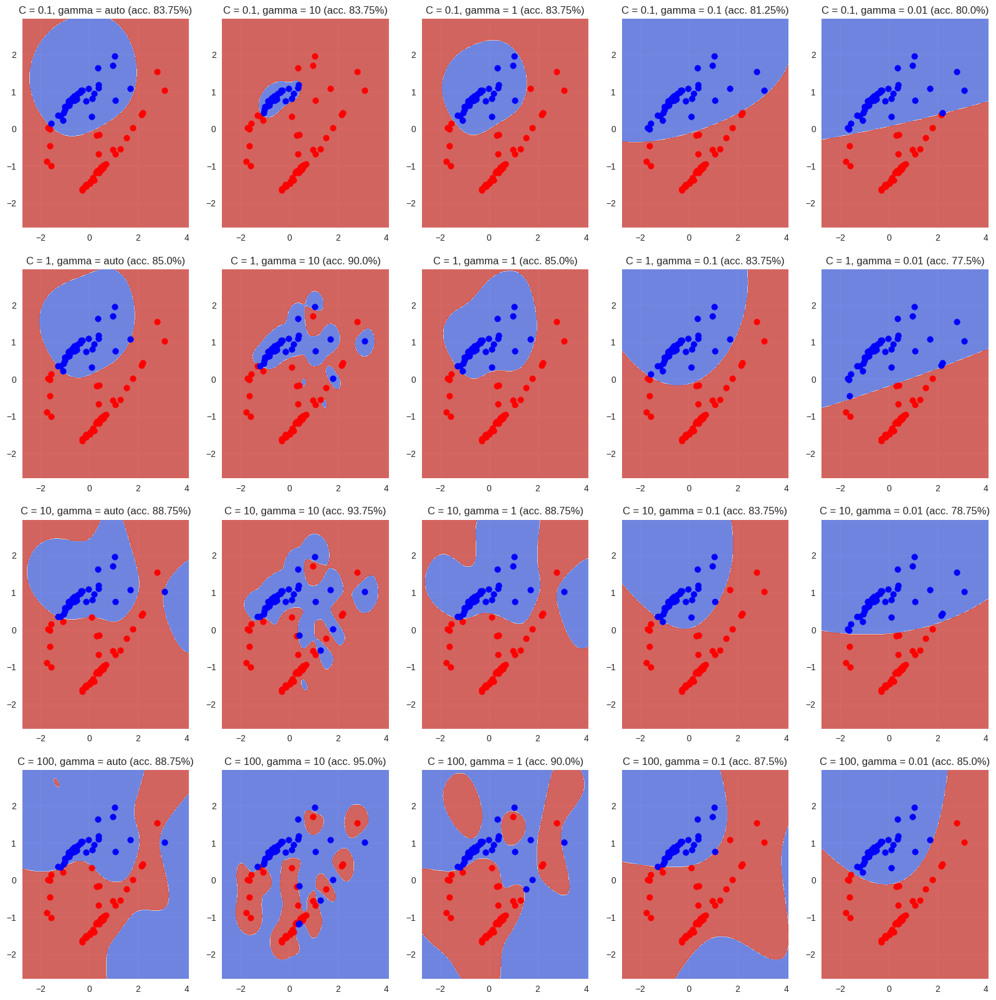

In [76]:
### START CODING ###
penalty = [0.1, 1, 10, 100]
gamma = ['auto', 10, 1, 0.1, 0.01]  # scale [default], auto
                                    # or non-negative float

plt.figure(figsize=(20,20))

for i in range(len(penalty)):
    for j in range(len(gamma)):

        model = sklearn.svm.SVC(C=penalty[i], gamma=gamma[j])
        model.fit(Y, labels_gt)
        labels_pred_rbf = model.predict(Y)

        plt.subplot(len(penalty), len(gamma), i*len(gamma)+j+1)
        #for representation purposes
        h = 0.02
        x_min, x_max = Y[:,0].min() -1 , Y[:,0].max() +1
        y_min, y_max = Y[:,1].min() -1 , Y[:,1].max() +1
        xx, yy = np.meshgrid(np.arange(x_min,x_max,h), np.arange(y_min, y_max,h))

        #display the boundary by predicting on every point on the grid
        Z = model.predict(np.c_[ xx.ravel(), yy.ravel()])
        # Put the result into color plot
        Z = Z.reshape(xx.shape)
        plt.contourf(xx, yy, Z, cmap = plt.cm.coolwarm, alpha = 0.8)

        plt.xlim(xx.min(), xx.max());
        plt.ylim(yy.min(), yy.max());

        acc_rbf = sklearn.metrics.accuracy_score(labels_gt, labels_pred_rbf)

        plt.scatter(Y[labels_pred_rbf==1,0],Y[labels_pred_rbf==1,1],c='r')
        plt.scatter(Y[labels_pred_rbf==0,0],Y[labels_pred_rbf==0,1],c='b')
        plt.title(f'C = {penalty[i]}, gamma = {gamma[j]} (acc. {acc_rbf*100}%)')
### END CODING ###

### Observation

Different values of `C` and `gamma` may greatly influence the description of the RBF model.
We may have very simple discrimination models (i.e. `C=1` and `gamma=0.01`) or very complex ones (i.e. `C=100` and `gamma=10`).

The underfitting occurs whenever the model is simplicistic that the accuracy is not that good (i.e. `C=1` and `gamma=0.01` or `C=10` and `gamma=0.01`).
On the other hand, overfitting occurs whenever the model is so complex that it is specifically designed for the training data (i.e. `C=100` and `gamma=10` or `C=10` and `gamma=10`), which means it may be not successfull in recognising the class of new data.

The parameter `C` is related to the margin of the classifier: the higher the `C`, the smaller the margin depth.
It's easier for the model to overfit with high values of `C`: having a smaller margin forces the classification curves to be very selective around the training data.

The parameter `gamma` is related to the inverse of the radius of influence of each data upon the model description: lower `gamma` values (higher radius values) state that the classification should not be specialized around each single point, while higher `gamma` values (smaller radius values) force the classifier to specialize around each signel point.

# Exercise 11. Support Vector Machine
Cluster the PCA projected data into **2** groups using k-Means (see sklearn.cluster.KMeans).

In [77]:
### START CODING ###
input = Y
model_ksvm = sklearn.cluster.KMeans(n_clusters=2)
model_ksvm.fit(input, labels_gt)
labels = model_ksvm.predict(input)
### END CODING ###

acc = sklearn.metrics.accuracy_score(labels_gt, labels)
# Account for possible inversion
if 1-acc > acc:
  acc = 1-acc
  labels = 1 - labels

print(f'Accuracy: {acc*100}%')

Accuracy: 75.0%


Represent the scatterplots of the original data and the two resultant clusters. Plot the final k-Means centroids as well.

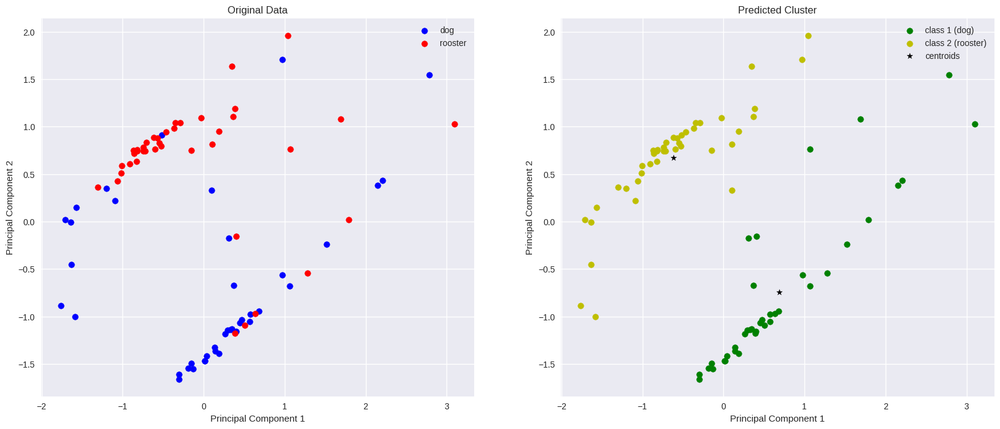

In [78]:
plt.figure(figsize=(20,8))

#Ground Truth Data
plt.subplot(1,2,1)
plt.scatter(input[labels_gt==1,0], input[labels_gt==1,1], c='b')
plt.scatter(input[labels_gt==0,0], input[labels_gt==0,1], c='r')
plt.title('Original Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(('dog', 'rooster'))

#Classification Result
plt.subplot(1,2,2)
plt.scatter(input[labels==1,0], input[labels==1,1], c='g')
plt.scatter(input[labels==0,0], input[labels==0,1], c='y')
plt.title('Predicted Cluster')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.scatter(model_ksvm.cluster_centers_[:,0], model_ksvm.cluster_centers_[:,1], color='black', marker='*')
plt.legend(('class 1 (dog)', 'class 2 (rooster)', 'centroids'));

#Exercise 12. k-NN
Fit a k-NN classifier (sklearn.neighbors.KNeighborsClassifier) to the same data and experiment with different k parameters. Discuss the results.

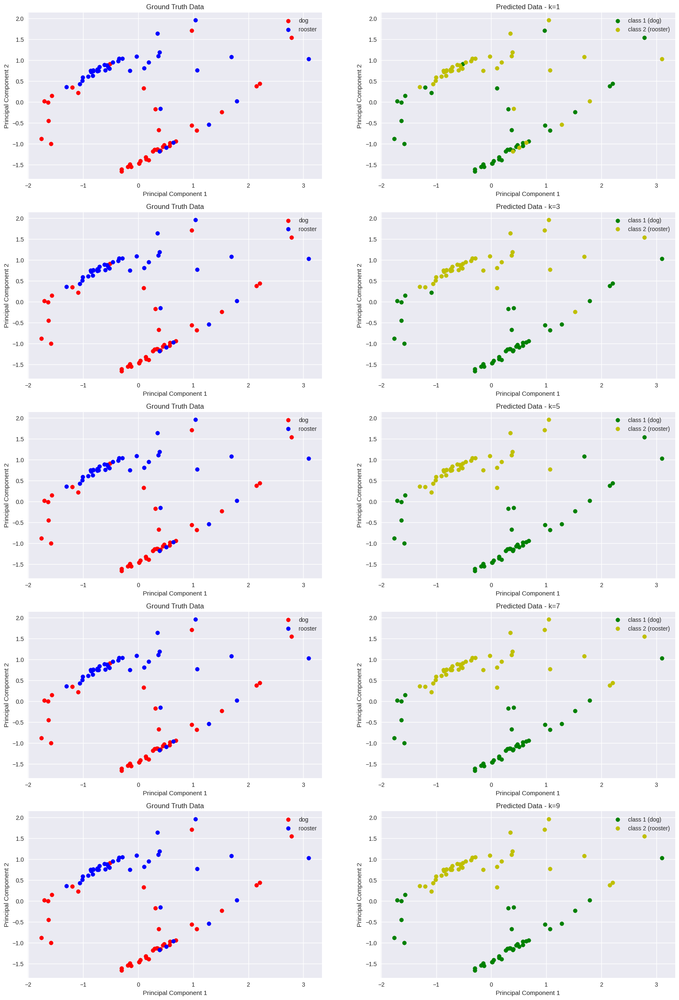

In [80]:
### START CODING ###
k = [1, 3, 5, 7, 9]


plt.figure(figsize=(20,30))

for i in range(len(k)):

    model_knn = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k[i])
    model_knn.fit(input, labels_gt)
    labels_knn = model_knn.predict(input)

    plt.subplot(len(k),2,2*i+1)
    plt.scatter(input[labels_gt==1,0], input[labels_gt==1,1], c='r')
    plt.scatter(input[labels_gt==0,0], input[labels_gt==0,1], c='b')
    plt.title('Ground Truth Data')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.legend(('dog', 'rooster'))

    plt.subplot(len(k),2,2*i+2)
    plt.scatter(input[labels_knn==1,0], input[labels_knn==1,1], c='g')
    plt.scatter(input[labels_knn==0,0], input[labels_knn==0,1], c='y')
    plt.title(f'Predicted Data - k={k[i]}')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.legend(('class 1 (dog)', 'class 2 (rooster)'))
### END CODING ###

### Observation

The parameter `k` for a k-NN classifier defines the number of neighbours to consider when describing the classifier: the classification of the data is based upon the observation of the $k$ nearest neighbours in the training data space.
The majority of a certain class presence (between the $k$ neighbours) determines the belonging to that specific class.

A low value of `k` (such as `k=1`) describes the classification based only on the nearest traning point, while a high value (such as `k=7`) forces the model to consider all the 7 nearest points.
This means that higher `k` values will discriminate the two classes in a more clustered way, while lower `k` values may take into account the presence of single class points.

The case `k=1` describes an overfitting: the classification is very good regarding the training points, but that doesn't necessarely mean the classification is actually good.
On the other hand, values like `k=7` or `k=9` will detach the classifier from the training data and try to describe more distinct classes.